# Pipeline Outputs & Methodology Showcase (Telup Dataset)

Dedicated notebook to inspect and export **publication-ready English figures** for every stage of the pipeline:
1. Uniform 120-Frame Sampling
2. Photometric Normalization (CLAHE on LAB L-Channel + Luminance Histogram)
3. Track A: MediaPipe 52-Landmark Overlay + Geometric Signals (`EAR`, `MAR`, `Pitch`, `Yaw`, `Roll`)
4. Track A: Temporal Sequence Augmentation (Scaling, Gaussian Noise, Frame Dropout)
5. Track B: Face ROI Bounding Box & `112x112` Cropped Clip
6. Saved Model Results (`summary_comparison.csv`, Training Curves, & Efficiency Trade-off)
7. Explainable AI Showcase (`SHAP` vs. `3D Score-CAM`)


In [1]:
import sys
from pathlib import Path
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd
import pickle
import torch

sys.path.insert(0, str(Path.cwd()))
from src.config import CONFIG, LEFT_EYE_LM, RIGHT_EYE_LM, MOUTH_LM
from src.preprocessing import scan_telup_videos, sample_uniform_frames, apply_clahe, create_face_landmarker
from src.datasets import build_point_feature_df, build_pixel_clip_df, PointSequenceDataset, compute_point_scaler, split_subject_independent

SHOWCASE_DIR = CONFIG.figures_dir / 'pipeline_showcase'
SHOWCASE_DIR.mkdir(parents=True, exist_ok=True)

df_videos = scan_telup_videos()
drowsy_row = df_videos[df_videos['label'] == 1].iloc[0]
nondrowsy_row = df_videos[df_videos['label'] == 0].iloc[0]
print('Drowsy sample   :', drowsy_row['subject'], drowsy_row['filename'])
print('Non-Drowsy sample:', nondrowsy_row['subject'], nondrowsy_row['filename'])
print('Showcase output dir:', SHOWCASE_DIR)


Drowsy sample   : subject_01 front_microsleep.mp4
Non-Drowsy sample: subject_01 front_focus.mp4
Showcase output dir: C:\Users\User\tugas akhir\results\telup\figures\pipeline_showcase


## 1. Uniform 120-Frame Sampling


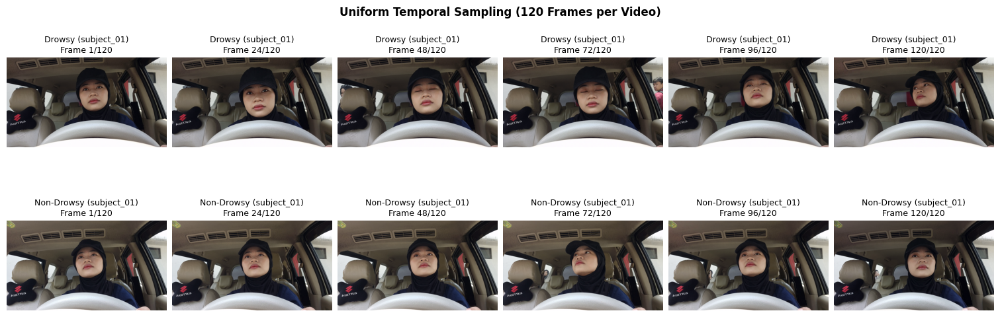

In [2]:
frames_drowsy = sample_uniform_frames(drowsy_row['video_path'], CONFIG.seq_len)
frames_nondrowsy = sample_uniform_frames(nondrowsy_row['video_path'], CONFIG.seq_len)
key_idx = np.linspace(0, CONFIG.seq_len - 1, 6, dtype=int)

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2), layout='constrained')
for r, (frames, title) in enumerate([(frames_drowsy, f"Drowsy ({drowsy_row['subject']})"),
                                     (frames_nondrowsy, f"Non-Drowsy ({nondrowsy_row['subject']})")]):
    for c, idx in enumerate(key_idx):
        axes[r, c].imshow(frames[idx])
        axes[r, c].set_title(f'{title}\nFrame {idx + 1}/120', fontsize=9)
        axes[r, c].axis('off')
fig.suptitle('Uniform Temporal Sampling (120 Frames per Video)', fontweight='bold')
fig.savefig(SHOWCASE_DIR / '01_uniform_sampling.png', dpi=180)
plt.show(); plt.close(fig)


## 2. Photometric Normalization (CLAHE on LAB L-Channel)


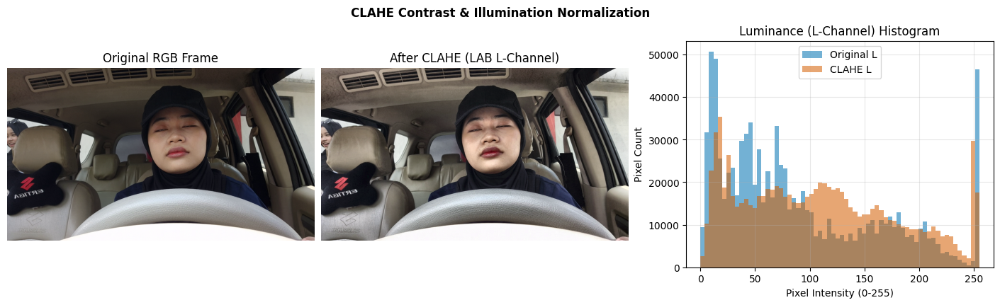

In [3]:
sample_frame = frames_drowsy[len(frames_drowsy) // 2]
clahe_frame = apply_clahe(sample_frame)

l_orig = cv2.cvtColor(sample_frame, cv2.COLOR_RGB2LAB)[:, :, 0]
l_clahe = cv2.cvtColor(clahe_frame, cv2.COLOR_RGB2LAB)[:, :, 0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout='constrained')
axes[0].imshow(sample_frame); axes[0].set_title('Original RGB Frame'); axes[0].axis('off')
axes[1].imshow(clahe_frame); axes[1].set_title('After CLAHE (LAB L-Channel)'); axes[1].axis('off')
axes[2].hist(l_orig.ravel(), bins=64, range=(0, 255), alpha=0.55, color='#0072B2', label='Original L')
axes[2].hist(l_clahe.ravel(), bins=64, range=(0, 255), alpha=0.55, color='#D55E00', label='CLAHE L')
axes[2].set(title='Luminance (L-Channel) Histogram', xlabel='Pixel Intensity (0-255)', ylabel='Pixel Count')
axes[2].legend(); axes[2].grid(True, alpha=0.3)
fig.suptitle('CLAHE Contrast & Illumination Normalization', fontweight='bold')
fig.savefig(SHOWCASE_DIR / '02_clahe_comparison.png', dpi=180)
plt.show(); plt.close(fig)


## 3. Track A — MediaPipe 52-Landmark Overlay & Geometric Signals


c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


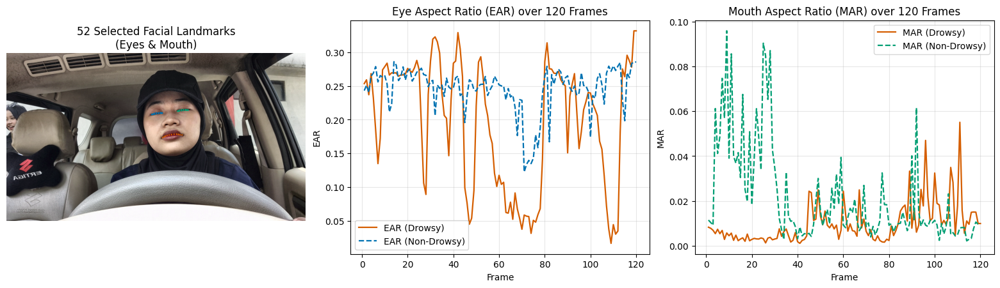

In [4]:
detector = create_face_landmarker()
res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=clahe_frame))
overlay = clahe_frame.copy()
h, w, _ = overlay.shape

if res.face_landmarks:
    lms = res.face_landmarks[0]
    for group, color in [(LEFT_EYE_LM, (0, 114, 178)), (RIGHT_EYE_LM, (0, 158, 115)), (MOUTH_LM, (213, 94, 0))]:
        for idx in group:
            cx, cy = int(lms[idx].x * w), int(lms[idx].y * h)
            cv2.circle(overlay, (cx, cy), 3, color, -1)

# Load pre-extracted 120x109 point sequence for Drowsy vs Non-Drowsy
df_pt = build_point_feature_df()
pt_drowsy_path = df_pt[df_pt['label'] == 1].iloc[0]['path']
pt_nondrowsy_path = df_pt[df_pt['label'] == 0].iloc[0]['path']
def _load_arr(p):
    d = pickle.load(open(p, 'rb'))
    return d['features'] if isinstance(d, dict) and 'features' in d else np.asarray(d)

seq_d, seq_nd = _load_arr(pt_drowsy_path), _load_arr(pt_nondrowsy_path)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), layout='constrained')
axes[0].imshow(overlay); axes[0].set_title('52 Selected Facial Landmarks\n(Eyes & Mouth)'); axes[0].axis('off')
t = np.arange(1, CONFIG.seq_len + 1)
axes[1].plot(t, seq_d[:, 0], label='EAR (Drowsy)', color='#D55E00', lw=1.6)
axes[1].plot(t, seq_nd[:, 0], label='EAR (Non-Drowsy)', color='#0072B2', lw=1.6, ls='--')
axes[1].set(title='Eye Aspect Ratio (EAR) over 120 Frames', xlabel='Frame', ylabel='EAR'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[2].plot(t, seq_d[:, 1], label='MAR (Drowsy)', color='#D55E00', lw=1.6)
axes[2].plot(t, seq_nd[:, 1], label='MAR (Non-Drowsy)', color='#009E73', lw=1.6, ls='--')
axes[2].set(title='Mouth Aspect Ratio (MAR) over 120 Frames', xlabel='Frame', ylabel='MAR'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
fig.savefig(SHOWCASE_DIR / '03_track_a_landmarks_and_signals.png', dpi=180)
plt.show(); plt.close(fig)


## 4. Track A — Training-Only Temporal Augmentation Effect


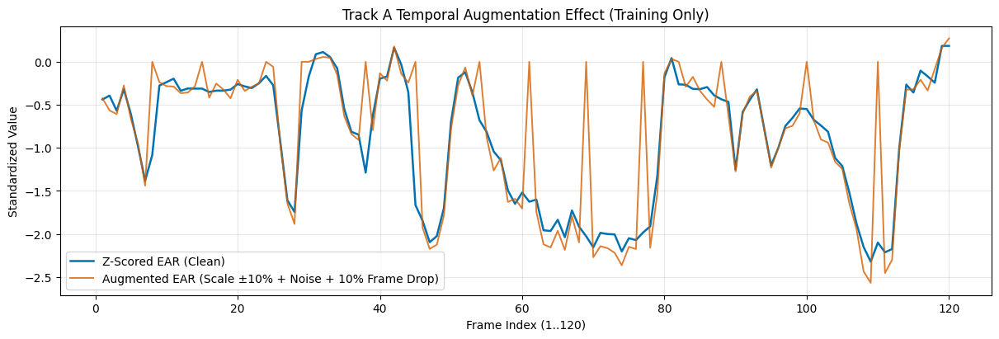

In [5]:
df_pt_tr, _ = split_subject_independent(df_pt)
s_mean, s_std = compute_point_scaler(df_pt_tr['path'].values)
ds_clean = PointSequenceDataset([pt_drowsy_path], [1], s_mean, s_std, augment=False)
ds_aug = PointSequenceDataset([pt_drowsy_path], [1], s_mean, s_std, augment=True)

torch.manual_seed(42)
x_clean, _ = ds_clean[0]
x_aug, _ = ds_aug[0]

fig, ax = plt.subplots(figsize=(12, 4.0), layout='constrained')
ax.plot(t, x_clean[:, 0].numpy(), label='Z-Scored EAR (Clean)', color='#0072B2', lw=1.8)
ax.plot(t, x_aug[:, 0].numpy(), label='Augmented EAR (Scale ±10% + Noise + 10% Frame Drop)', color='#D55E00', alpha=0.8, lw=1.4)
ax.set(title='Track A Temporal Augmentation Effect (Training Only)', xlabel='Frame Index (1..120)', ylabel='Standardized Value')
ax.legend(); ax.grid(True, alpha=0.3)
fig.savefig(SHOWCASE_DIR / '04_track_a_augmentation.png', dpi=180)
plt.show(); plt.close(fig)


## 5. Track B — Face ROI Detection & 112x112 Cropped Sequence


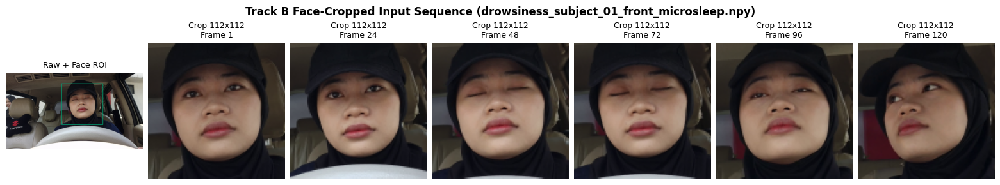

In [6]:
df_px = build_pixel_clip_df()
px_row = df_px[df_px['label'] == 1].iloc[0]
clip_112 = np.load(px_row['path'])  # (120, 112, 112, 3)

# Draw bounding box on original frame for comparison
bbox_frame = sample_frame.copy()
res_raw = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=bbox_frame))
if res_raw.face_landmarks:
    xs = np.array([lm.x * bbox_frame.shape[1] for lm in res_raw.face_landmarks[0]])
    ys = np.array([lm.y * bbox_frame.shape[0] for lm in res_raw.face_landmarks[0]])
    side = max(xs.max() - xs.min(), ys.max() - ys.min()) * (1.0 + 2.0 * CONFIG.face_crop_margin)
    cx, cy = (xs.min() + xs.max()) / 2.0, (ys.min() + ys.max()) / 2.0
    x1, y1 = max(0, int(cx - side / 2)), max(0, int(cy - side / 2))
    x2, y2 = min(bbox_frame.shape[1], int(cx + side / 2)), min(bbox_frame.shape[0], int(cy + side / 2))
    cv2.rectangle(bbox_frame, (x1, y1), (x2, y2), (0, 158, 115), 3)

fig, axes = plt.subplots(1, 7, figsize=(15.5, 2.8), layout='constrained')
axes[0].imshow(bbox_frame); axes[0].set_title('Raw + Face ROI', fontsize=9); axes[0].axis('off')
for ax, idx in zip(axes[1:], key_idx):
    ax.imshow(clip_112[idx]); ax.set_title(f'Crop 112x112\nFrame {idx + 1}', fontsize=9); ax.axis('off')
fig.suptitle(f"Track B Face-Cropped Input Sequence ({px_row['filename']})", fontweight='bold')
fig.savefig(SHOWCASE_DIR / '05_track_b_face_crop.png', dpi=180)
plt.show(); plt.close(fig)


## 6. Saved Quantitative Results & Model Comparison


,Track,Model,Total_Params,Trainable_Params,GFLOPs,Size_KB,Latency_ms,CV_Val_Loss,CV_Acc (%),CV_Acc_SD (%),CV_F1 (%),CV_F1_SD (%),Test_Acc (%),Test_Prec (%),Test_Rec (%),Test_F1 (%)
0,Track B,3D ResNet,33031106,24777730,124.837431,129027.76,86.367,0.6081,76.67,11.26,76.05,11.52,85.0,93.75,75.0,83.33
1,Track B,3D ResNeXt,47525314,16318466,143.747244,185645.76,106.383,0.5680,75.83,6.18,74.35,6.11,80.0,77.27,85.0,80.95
2,Track B,3D WideResNet,157432770,98598914,395.142963,614971.76,202.500,0.5413,76.67,4.75,77.49,5.45,92.5,90.48,95.0,92.68
3,Track A,CNN,20770,20770,0.004923,81.13,0.917,0.5680,75.00,2.95,75.26,2.99,82.5,80.95,85.0,82.93
4,Track A,LSTM,36866,36866,0.008663,144.01,1.371,0.5841,78.33,9.95,79.14,9.12,80.0,83.33,75.0,78.95
5,Track A,RNN,9410,9410,0.004332,36.76,16.405,0.6011,66.67,5.10,64.43,8.18,72.5,76.47,65.0,70.27
6,Track A,TRANSFORMER KD,8706,8706,0.000419,34.01,3.118,0.6251,65.83,12.29,64.91,18.87,77.5,76.19,80.0,78.05
7,Track A,TRANSFORMER KD+QAT,8706,8706,0.000419,8.50,6.052,0.6258,65.83,12.29,64.91,18.87,77.5,76.19,80.0,78.05
8,Track A,TRANSFORMER STUDENT,8706,8706,0.000419,34.01,2.126,0.6478,62.50,12.84,60.63,17.69,75.0,75.00,75.0,75.00
9,Track A,TRANSFORMER TEACHER,42914,42914,0.000839,167.63,2.755,0.5817,73.33,8.12,73.06,8.98,80.0,80.00,80.0,80.00


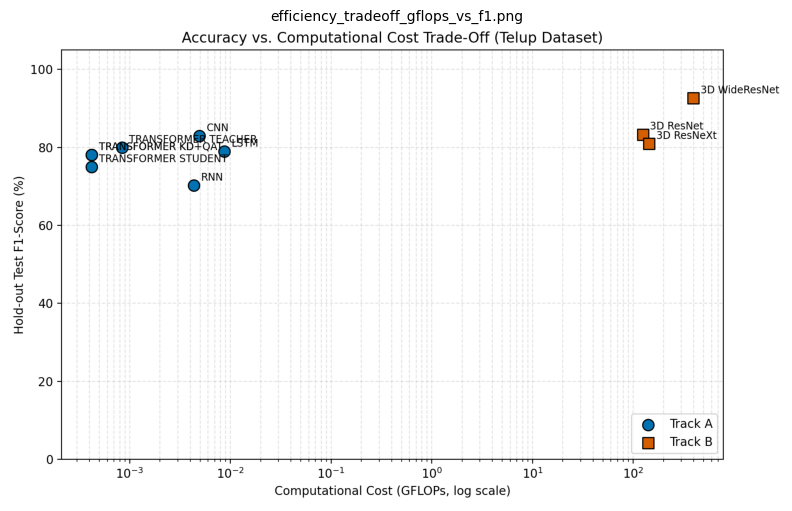

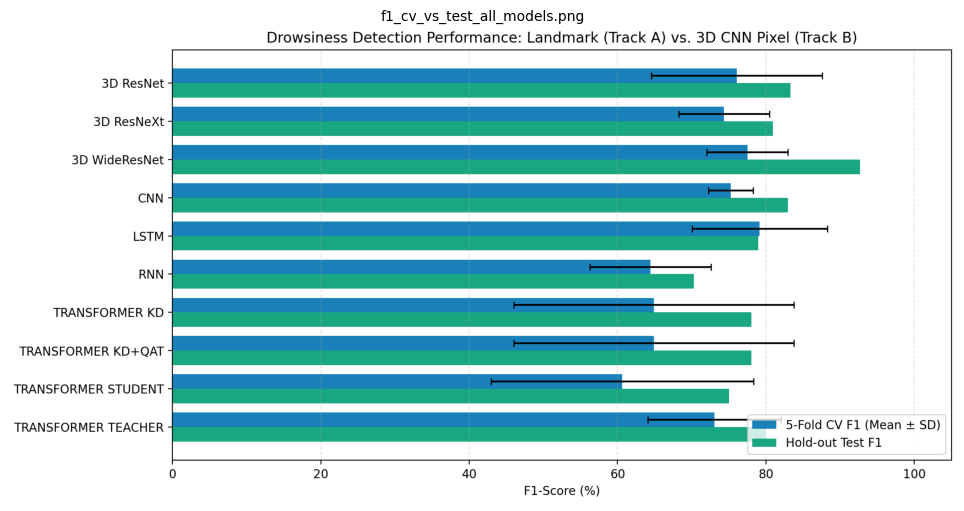

In [7]:
summary_csv = CONFIG.tables_dir / 'summary_comparison.csv'
if summary_csv.exists():
    display(pd.read_csv(summary_csv))
else:
    print('Run Section 6 in main_telup_point_vs_pixel.ipynb to generate summary_comparison.csv')

for fig_path in sorted((CONFIG.figures_dir / 'comparison').glob('*.png')):
    fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
    ax.imshow(mpimg.imread(fig_path)); ax.axis('off'); ax.set_title(fig_path.name, fontsize=10)
    plt.show(); plt.close(fig)


## 7. Saved XAI Outputs Showcase (SHAP vs. 3D Score-CAM)


=== xai_shap (3 figures) ===


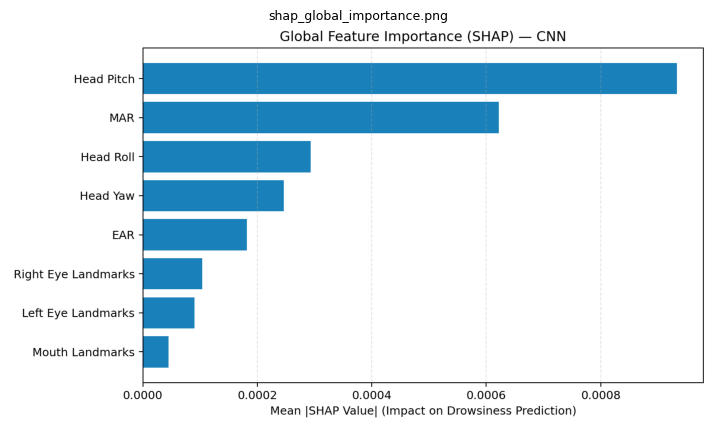

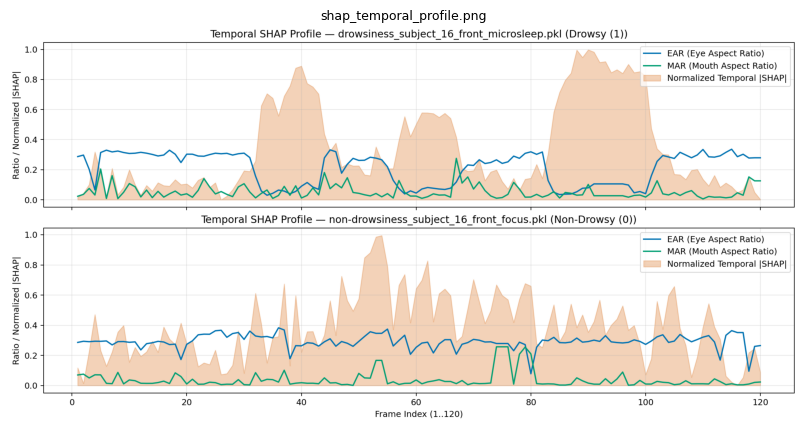

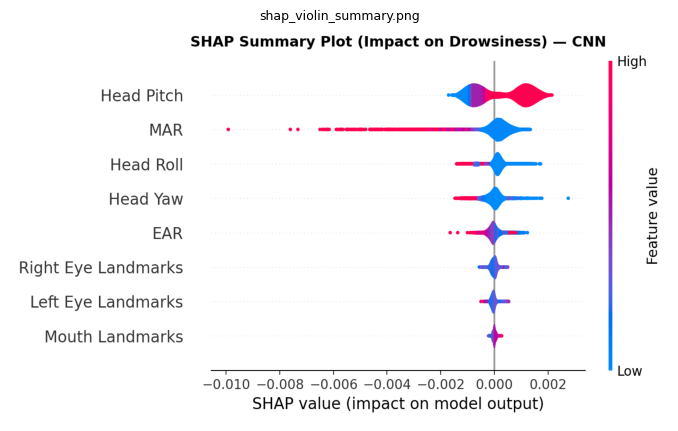

=== xai_scorecam (20 figures) ===


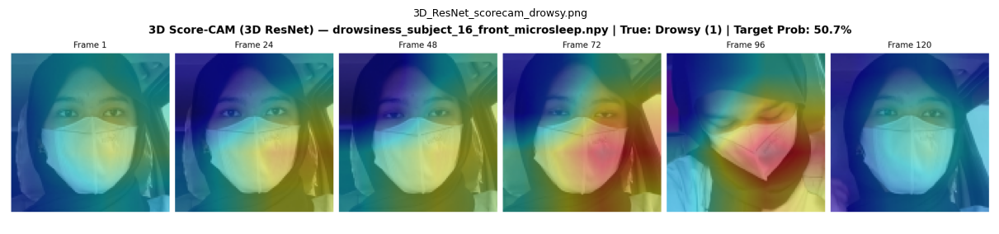

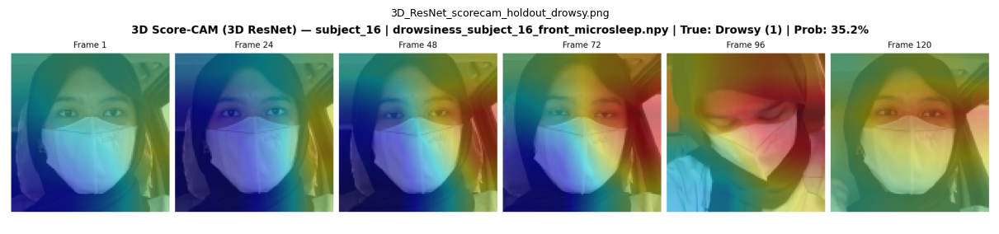

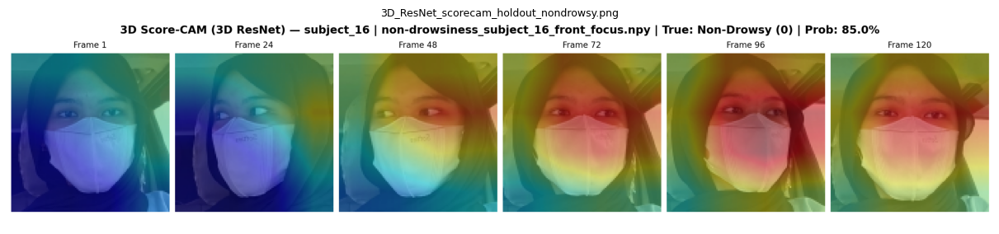

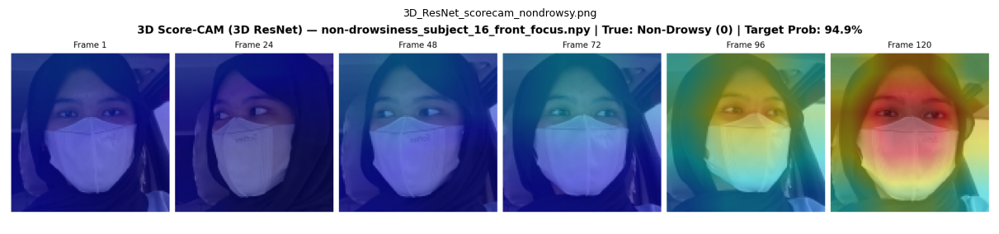

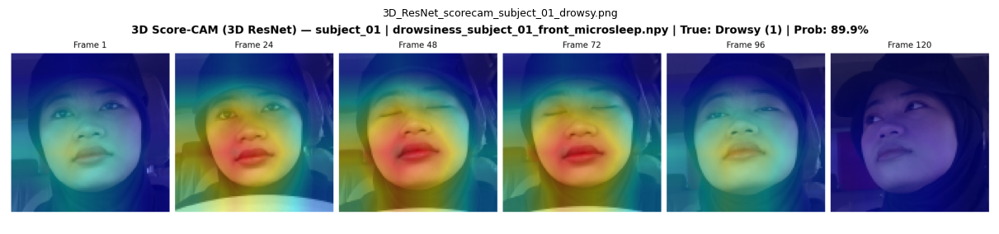

...

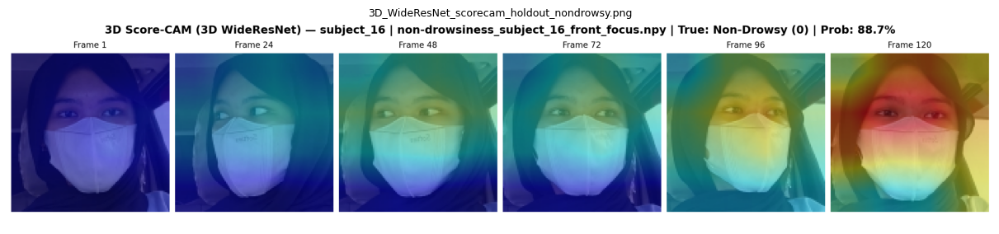

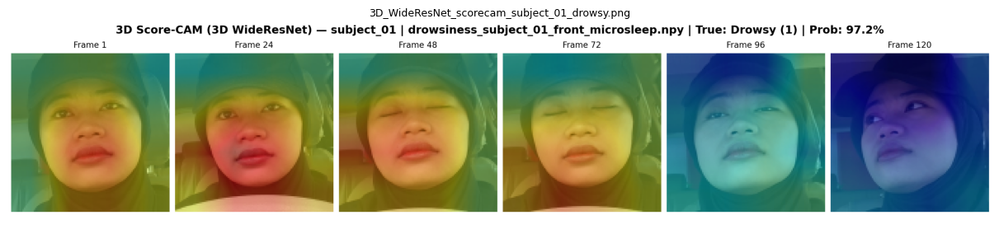

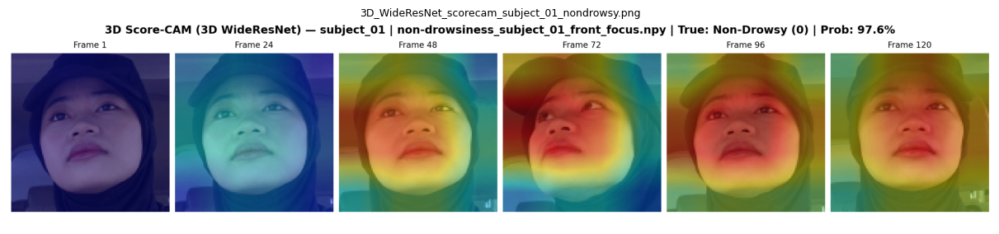

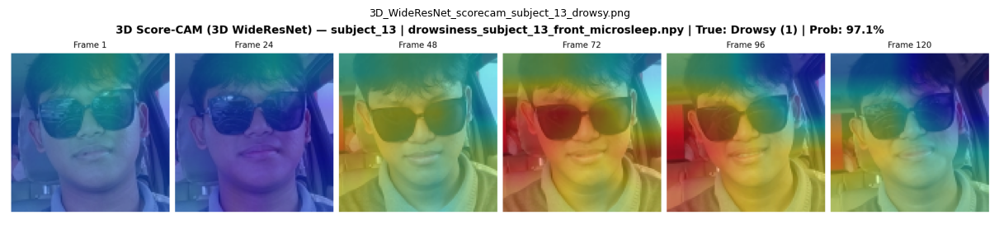

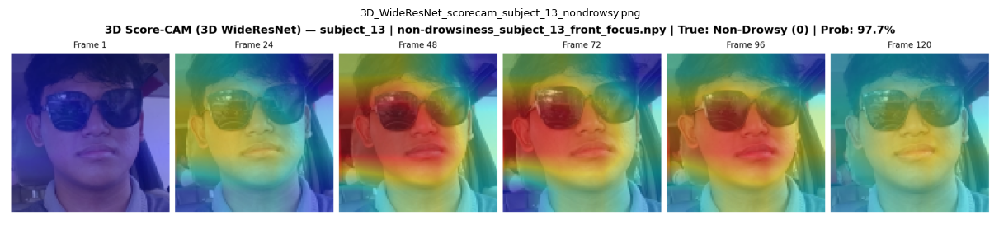

In [8]:
for folder_name in ['xai_shap', 'xai_scorecam']:
    imgs = sorted((CONFIG.figures_dir / folder_name).glob('*.png'))
    print(f'=== {folder_name} ({len(imgs)} figures) ===')
    for p in imgs:
        fig, ax = plt.subplots(figsize=(12, 4.2), layout='constrained')
        ax.imshow(mpimg.imread(p)); ax.axis('off'); ax.set_title(p.name, fontsize=9)
        plt.show(); plt.close(fig)
